# 移动抓取轨迹：三维动画

读取 ROS 1 bag，无需启动 ROS。三维动画显示飞机和小车的轨迹、姿态箭头和 Z=0 地面；XY 动画还显示小车水平速度。运行全部单元格后，3D GIF 和 XY 平面 GIF 保存到 bag 同目录并显示在 notebook 中。

**坐标与时间**：按 RViz 配置使用 `world`，飞机姿态箭头为机体 +X，小车姿态箭头为刚体 +Y；速度箭头使用 twist 的线速度。小车消息若 `frame_id` 为空，将假设其数值与飞机处于同一世界坐标系，需自行确认。非空且不一致的 frame 会报错；本 notebook 不执行 TF 变换。使用 bag record time 同步，以 bag 开始为零点；采样间隔过大时隐藏对应物体，不跨缺口插值。轨迹仅显示记录位置，不代表抓取成功。

默认生成三维和 XY 平面 GIF；不需要三维 GIF 时可将 `MAKE_GIF` 设为 `False`。

GIF 播放与生成速度：`PLAYBACK_SPEED=2.0` 为约 2 倍速；提高倍速或降低 `FPS` 都会减少需要绘制的帧。`GIF_DPI` 控制输出分辨率，可分别用 `MAKE_GIF` 和 `MAKE_XY_GIF` 控制是否生成两种动画。这些参数不改变时序图和闭爪统计。

In [115]:
from pathlib import Path

BAG = Path('/Users/lzf/Documents/wfzf/2026-11-02-18-03-36.bag')
START_S = 0.0          # 相对 bag 开始时间，秒
END_S = None           # None 表示到数据共同结束时间
FPS = 8                # GIF 输出帧率；降低可减少帧数，动画也会不那么流畅
PLAYBACK_SPEED = 2.0   # GIF 播放倍速：1 实时、2 两倍速、0.5 半速
MAX_GAP_S = 0.25       # 两个采样之间超过此值不插值
HEADING_LENGTH_M = 0.35
VELOCITY_SCALE_S = 1.0 # 速度箭头长度 = 速度 × 此值
OUTPUT = BAG.with_name(BAG.stem + '_moving_grasp.gif')
MAKE_GIF = True        # 是否生成三维 GIF
MAKE_XY_GIF = True     # 是否生成 XY 平面 GIF
GIF_DPI = 100          # GIF 分辨率；如设为 70 可加快编码并减小文件
XY_GIF_OUTPUT = BAG.with_name(BAG.stem + '_moving_grasp_xy.gif')
TIMESERIES_OUTPUT = BAG.with_name(BAG.stem + '_moving_grasp_timeseries.png')
CLOSE_BURST_GAP_S = 1.0         # 相邻闭爪指令间隔超过此值视作新一轮

CLOSE_DURATION_S = 0.85  # 闭爪指令开始后的设定持续时间，秒
CAR_VELOCITY_CUTOFF_HZ = 3.0  # 小车 XY 速度低通截止频率；0 表示关闭
CAR_CURVATURE_MIN_SPEED_MPS = 0.10  # 低于此水平速度时不计算曲率
CAR_CURVATURE_WINDOW_S = 1.0       # 中心速度差分时间窗口，秒

## 闭爪条件证据图

先运行配置单元格，再运行此单元格，无需等待 GIF。前三行使用 bag 中规划器 `/drone0/planning/grasp_alignment` 记录的三维距离、三维相对速度和 yaw 误差，门限默认取 `/drone0/planning/rosparam_snapshot`。紫色虚线是与快照闭爪目标匹配的指令，黑色点线是 `/triger`。

第四行比较飞机 EKF yaw、小车速度方向经 3 Hz 滤波后的方向及继续经 1 Hz 滤波后的方向；第五行是三项数值在采样点的比较。底部是 **bag 录制证据**，不是规划器回调新鲜度。航向就绪、本次轨迹匹配、规划器内部连续计时和可行轨迹没有完整记录，不能由本图确认。若缺少 alignment 或门限，不能推断为通过或未通过。该图不能证明舵机实际闭合。

参数快照可能滞后，或参数被修改但规划器没有重读；因此快照只反映录到的参数服务器值。确实知道实际值且没有快照时，可填 `GATE_LIMITS_OVERRIDE`，覆盖值会标注为 manual。

默认显示第一次 `/triger` 前 2 s 至该次首次匹配的闭爪指令后 5 s。没有识别到闭爪指令时，显示到下次触发或 bag 结束；没有触发时使用可用录包范围并提示。多次触发可通过 `GATE_TRIGGER_INDEX` 选择（从 0 开始）。`START_S` 和 `END_S` 如果有设置，还会进一步限制范围。

航向曲线对小车 XY 速度向量逐级低通后计算角度，滤波频率优先读取 bag 中第一份规划快照；缺失时明确提示假定 3 Hz 和 1 Hz。第二级尽可能按录到的规划采样时刻更新，低速或数据间断时不绘制。它是离线近似，不能代替规划器内部的方向就绪和实际目标 yaw；飞机 yaw 取 EKF 机体 +X，小车画的是速度方向，不是动捕刚体姿态。曲线做角度展开以避免 ±180° 跳线。

闭爪条件证据图: /Users/lzf/Documents/wfzf/2026-11-02-18-03-36_grasp_gate_conditions.png
小车航向离线滤波: 3 Hz → 1 Hz，偏置 0 rad；第二级时间采样: alignment samples
第 2/2 次触发 37.198 s；匹配闭爪指令 45.716 s；绘图范围 35.198–50.716 s
匹配快照闭爪目标的指令分组时刻: 45.716 s
规划器 alignment 样本: 191; approach 阶段样本: 153
  grasp_start_dis: 未通过 137/153 个已知样本; 门限来源 snapshot
  grasp_max_relative_speed: 未通过 146/153 个已知样本; 门限来源 snapshot
  grasp_max_yaw_error: 未通过 129/153 个已知样本; 门限来源 snapshot
三项数值同时满足: 5/153 个已知样本; 最长连续采样区间 0.175 s（不是规划器内部计时）；快照 gate_duration: 0.15 s
相关规划日志（所选时间内最后 10 条）:
  45.716s [planner] Closing for 0.850 s while tracking; no gripper feedback required
  46.616s [planner] Close timer complete; lifting while following the car
  47.669s [planner] Flight trajectory control lost during approach; controlled brake then abort hold (new trigger required)
注意：参数快照是录包时参数服务器记录，不保证运行中被规划器重新读取。
限制：数值通过、bag 记录新鲜和飞行状态字段均不能证明完整闭爪门限通过；航向就绪、任务轨迹匹配、回调/时间戳新鲜度、内部连续计时和可行轨迹仍需证据。


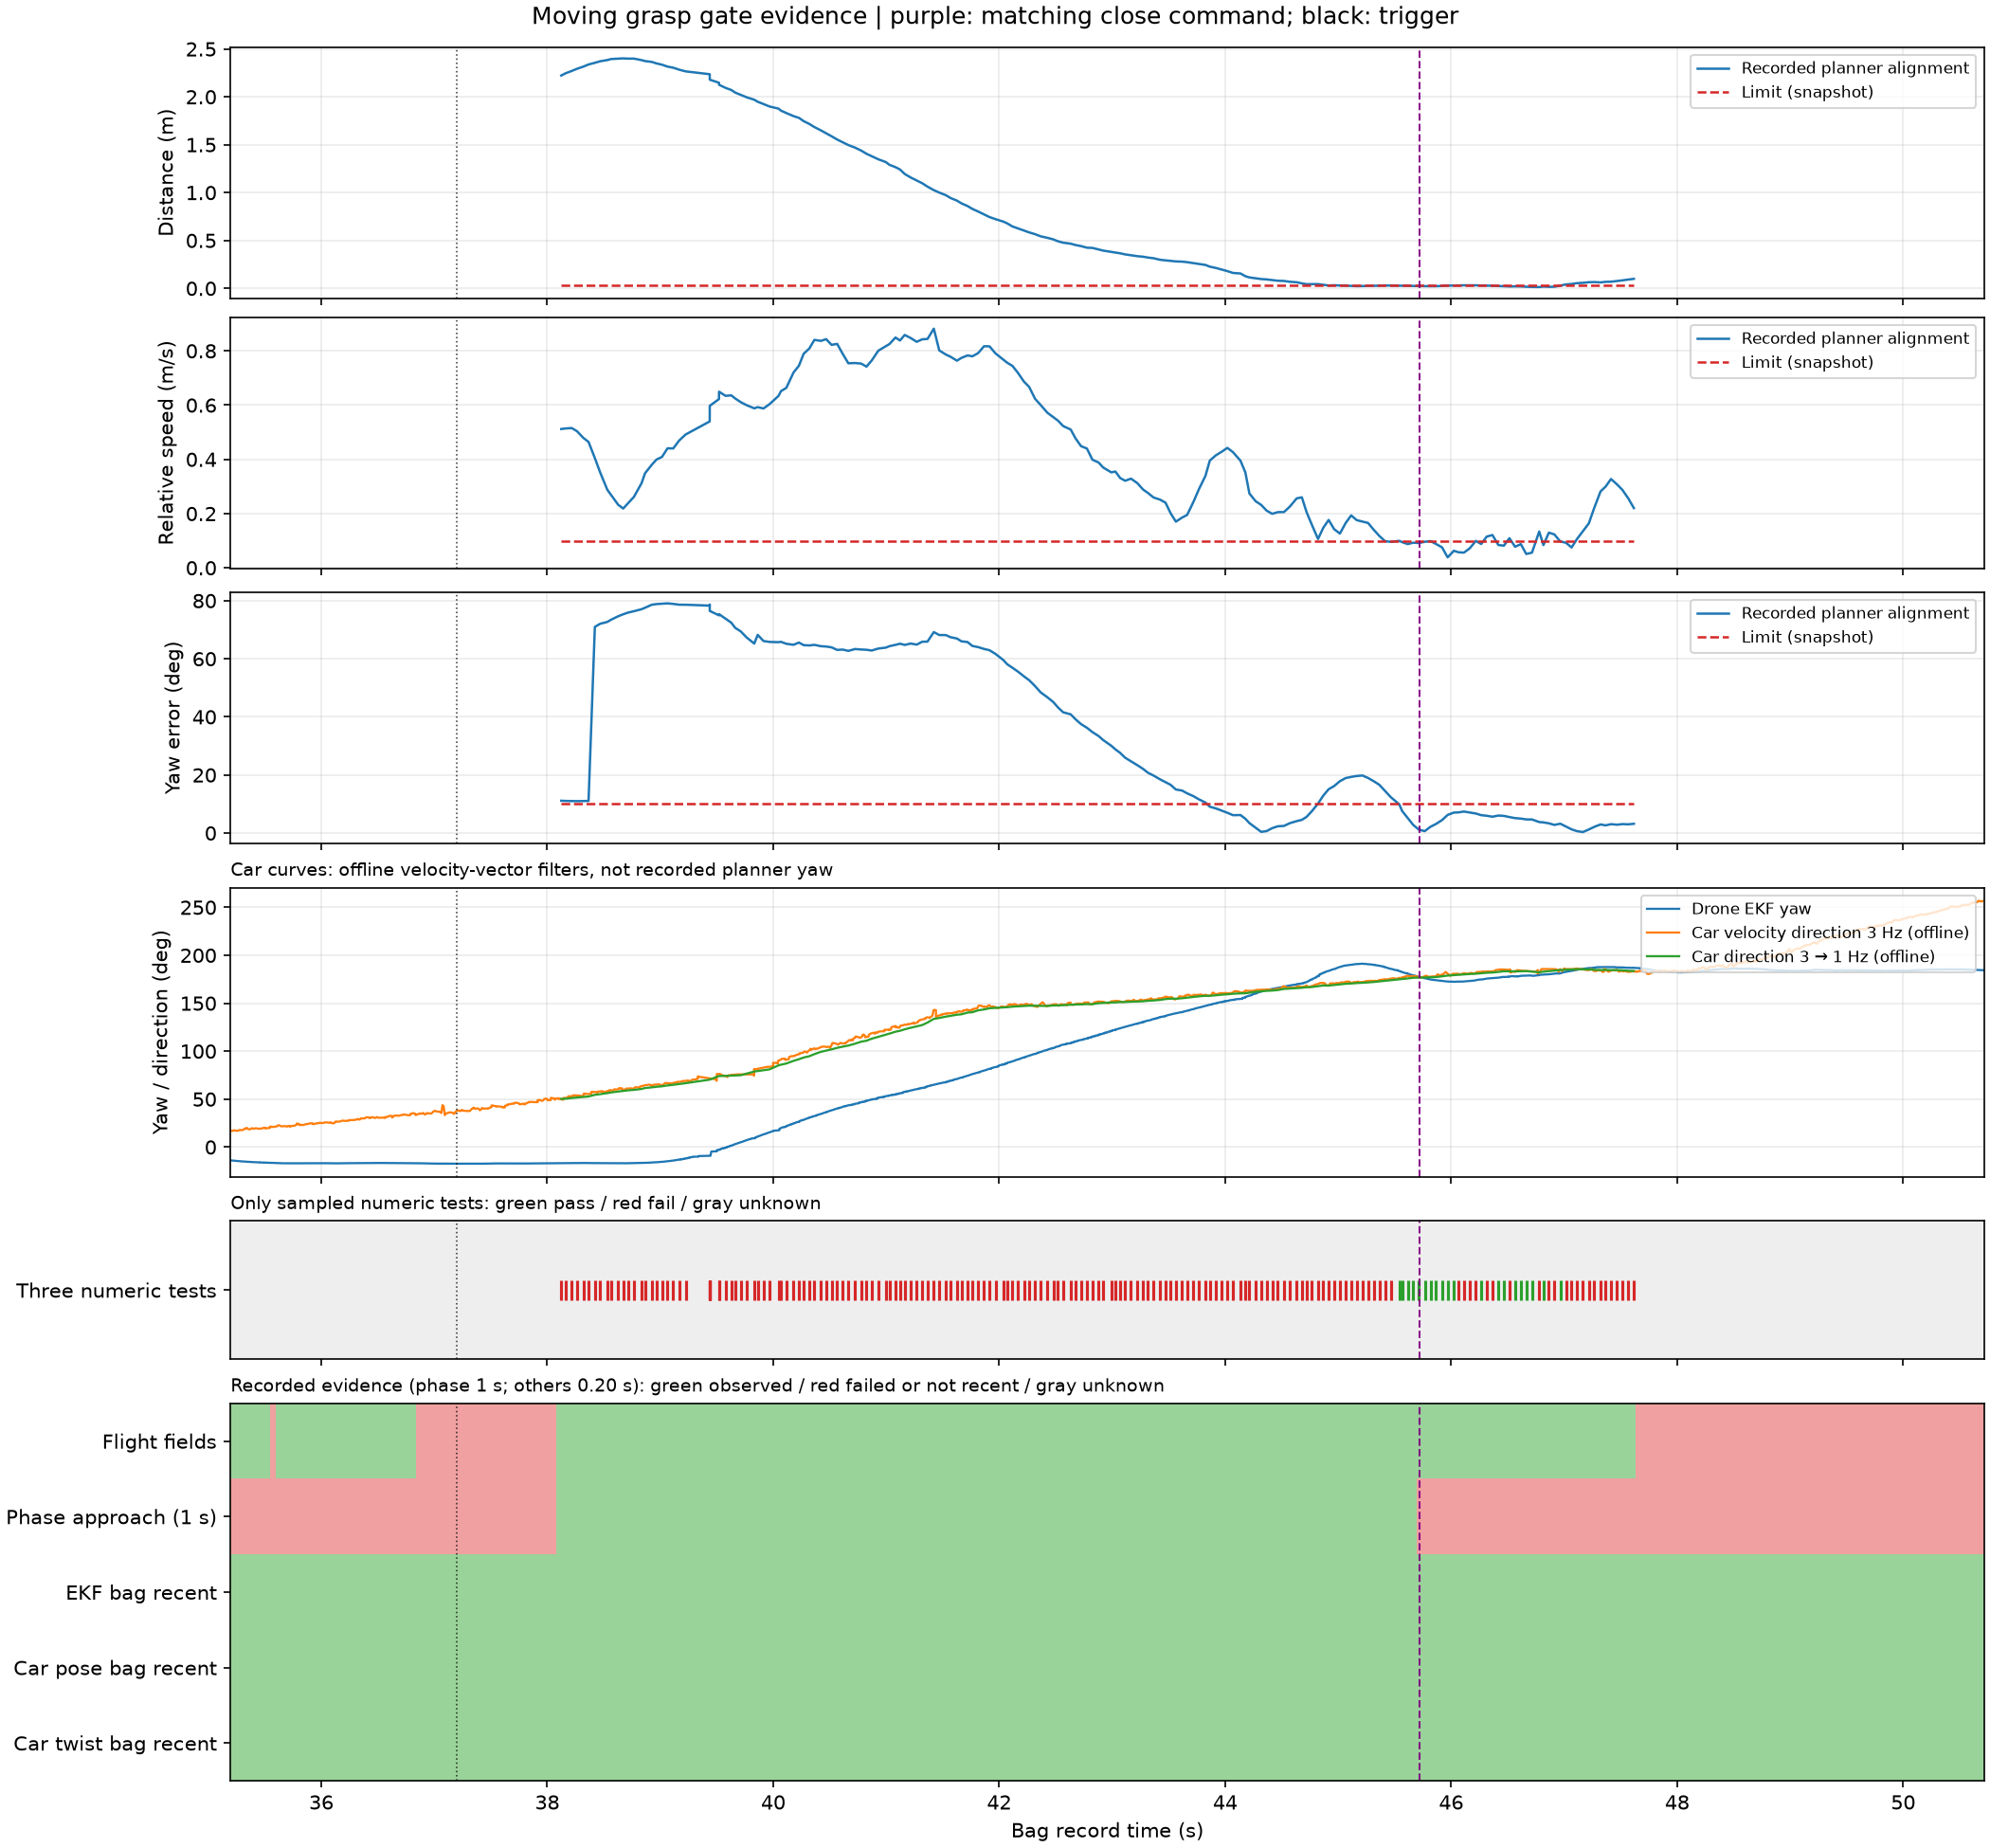

In [116]:
# 不依赖后面的时序图和 GIF 单元格，可单独运行。
import sys
import importlib
from pathlib import Path
from IPython.display import Image, display

_candidates = [Path.cwd() / 'scripts', Path.cwd()]
_scripts_dir = next((p for p in _candidates if (p / 'analyze_moving_grasp_gate.py').is_file()), None)
if _scripts_dir is None:
    raise FileNotFoundError('请从 HIARM 仓库根目录或 scripts 目录启动 Notebook')
if str(_scripts_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(_scripts_dir.resolve()))
import analyze_moving_grasp_gate
importlib.reload(analyze_moving_grasp_gate)  # Notebook 内核已运行时也加载最新代码

# 通常保持空字典，自动读取 bag 快照；仅在已确认实际参数时填写，例如：
# GATE_LIMITS_OVERRIDE = {'grasp_start_dis': 0.02, 'grasp_max_relative_speed': 0.10,
#                         'grasp_max_yaw_error': 0.174533}  # 单位分别为 m、m/s、rad
GATE_LIMITS_OVERRIDE = {}
GATE_TRIGGER_INDEX = 1  # 选择第几次 /triger：0 为第一次，1 为第二次
GATE_OUTPUT = BAG.with_name(BAG.stem + '_grasp_gate_conditions.png')
gate_summary = analyze_moving_grasp_gate.plot_gate_conditions(BAG, GATE_OUTPUT, start_s=START_S, end_s=END_S,
    overrides=GATE_LIMITS_OVERRIDE, close_burst_gap_s=CLOSE_BURST_GAP_S,
    plot_max_gap_s=MAX_GAP_S, trigger_index=GATE_TRIGGER_INDEX)
display(Image(filename=str(GATE_OUTPUT)))

In [117]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from rosbags.highlevel import AnyReader
from IPython.display import Image, display

TOPICS = {'drone': '/ekf/ekf_odom', 'car': '/vrpn_client_node/HIARM_car/pose',
          'velocity': '/vrpn_client_node/HIARM_car/twist'}

def read_data(path):
    rows = {key: [] for key in TOPICS}
    frames = {key: set() for key in TOPICS}
    with AnyReader([path]) as reader:
        bag_start = reader.start_time * 1e-9
        connections = [c for c in reader.connections if c.topic in TOPICS.values()]
        missing = set(TOPICS.values()) - {c.topic for c in connections}
        if missing:
            raise ValueError(f'bag 缺少话题: {sorted(missing)}')
        by_topic = {v: k for k, v in TOPICS.items()}
        for connection, timestamp, raw in reader.messages(connections=connections):
            key = by_topic[connection.topic]
            msg = reader.deserialize(raw, connection.msgtype)
            frames[key].add(msg.header.frame_id.strip().lstrip('/'))
            if key == 'velocity':
                v = msg.twist.linear
                values = [v.x, v.y, v.z]
            else:
                pose = msg.pose.pose
                p, q = pose.position, pose.orientation
                values = [p.x, p.y, p.z, q.x, q.y, q.z, q.w]
            if np.isfinite(values).all():
                rows[key].append([timestamp * 1e-9 - bag_start, *values])
    for key in rows:
        a = np.asarray(rows[key], dtype=float)
        if len(a) < 2:
            raise ValueError(f'{TOPICS[key]} 有效样本不足')
        a = a[np.argsort(a[:, 0], kind='stable')]
        _, idx = np.unique(a[:, 0], return_index=True)
        rows[key] = a[idx]
    named = {f for fs in frames.values() for f in fs if f}
    if named - {'world'}:
        raise ValueError(f'发现非 world 坐标系 {named}，请先做 TF 变换')
    if any('' in fs for fs in frames.values()):
        warnings.warn('存在空 frame_id：假设这些数据与 world 同坐标系，请核实。')
    for key, a in rows.items():
        print(f'{TOPICS[key]}: {len(a)} 条有效样本, {a[0,0]:.3f}–{a[-1,0]:.3f} s, frame_id={frames[key]}')
    return rows

def filter_car_velocity_xy(velocity, cutoff_hz, max_gap_s):
    """Use record-time dt; reset on a gap. Filter components before speed norm."""
    if not np.isfinite(cutoff_hz) or cutoff_hz < 0 or not np.isfinite(max_gap_s) or max_gap_s <= 0:
        raise ValueError('截止频率须为有限非负值，MAX_GAP_S 须为有限正值')
    filtered = velocity.copy()
    if cutoff_hz == 0:
        return filtered
    for i in range(1, len(filtered)):
        dt = velocity[i, 0] - velocity[i-1, 0]
        if dt <= 0 or dt > max_gap_s:
            filtered[i, 1:3] = velocity[i, 1:3]
        else:
            alpha = -np.expm1(-2 * np.pi * cutoff_hz * dt)
            filtered[i, 1:3] = filtered[i-1, 1:3] + alpha * (velocity[i, 1:3] - filtered[i-1, 1:3])
    return filtered

data = read_data(BAG)
car_velocity_filtered = filter_car_velocity_xy(data['velocity'], CAR_VELOCITY_CUTOFF_HZ, MAX_GAP_S)

/ekf/ekf_odom: 9296 条有效样本, 0.000–55.169 s, frame_id={'world'}
/vrpn_client_node/HIARM_car/pose: 4548 条有效样本, 0.122–55.162 s, frame_id={''}
/vrpn_client_node/HIARM_car/twist: 4537 条有效样本, 0.123–55.162 s, frame_id={''}


/var/folders/fb/0jg6j9p93lz9dgn6sq0npjfh0000gn/T/ipykernel_26697/3018427632.py:45: UserWarning: 存在空 frame_id：假设这些数据与 world 同坐标系，请核实。
  warnings.warn('存在空 frame_id：假设这些数据与 world 同坐标系，请核实。')


## 位置、水平速度、转弯半径与闭爪指令
五个子图分别显示世界坐标 X、Y、Z 位置、水平速度大小 `sqrt(vx² + vy²)` 和小车水平轨迹的转弯半径，横轴是相对 bag 开始的录包时间。无人机速度取 `/ekf/ekf_odom` 的 twist，小车速度取 `/vrpn_client_node/HIARM_car/twist`。闭爪标记取 `/flygripper/actuator_command` 中与规划参数 `grasp_position` 匹配的 MODE_POSITION 指令；连续重发只标记每轮第一条，间隔阈值可配置。

自动使用 `/drone0/planning/rosparam_snapshot` 中的闭爪目标；快照缺失或目标值冲突时会提示并跳过闭爪识别。指令标记仅说明 bag 记录到该目标的发布，不代表舵机收到命令或实际闭合。小车空 `frame_id` 时沿用前述世界坐标假设。

阴影表示从每组首次闭爪指令开始的设定持续时间（默认 0.85 秒），不代表实际闭合或期间持续发布。

小车水平速度同时显示原始值和滤波值：对 `vx`、`vy` 分别进行一阶低通，再求水平速度模长。`CAR_VELOCITY_CUTOFF_HZ` 默认 3 Hz，设为 0 关闭滤波；大于 `MAX_GAP_S` 的采样间隔会重置滤波器。滤波使用录包时间，结果不等同于规划器运行时的内部滤波状态。

转弯半径由滤波后小车 XY 速度估算：先计算有符号曲率 `κ = (vx·dvy/dt - vy·dvx/dt) / (vx² + vy²)^(3/2)`，再取 `R = 1 / |κ|`，单位为 m；半径不区分左右转。速度使用录包时间在 `CAR_CURVATURE_WINDOW_S`（默认 0.2 s）窗口两侧求差分。半径是离线估计，速度噪声和滤波延迟会影响结果。差分窗口内任一速度低于 `CAR_CURVATURE_MIN_SPEED_MPS`（默认 0.10 m/s）、相邻采样间隔超过 `MAX_GAP_S`，或窗口不完整时，该处不绘制。曲率为零时半径无穷大，不绘制该点；曲率接近零时半径可能很大且对噪声敏感，因此半径纵轴使用对数刻度。曲率符号改变时断开曲线，避免跨过无穷大连线。

同时输出每个闭爪窗口 `[开始, 开始 + CLOSE_DURATION_S)` 内小车原始及滤波后水平速度的采样最大值和时刻；覆盖检查要求窗口两端均有样本且间隔不超过 `MAX_GAP_S`。数据不完整时的最大值仅是已记录样本的最大值。每个窗口还输出首次闭爪指令时刻最近的曲率采样对应的转弯半径，并标明采样时刻；指令时刻必须位于连续数据范围内，且该采样的曲率必须有效，否则输出无法计算。该离线估计使用指令前后的数据，并非实际闭合时刻或实时测量。

闭爪目标: -12.7 rad (planner snapshot); 匹配指令 189 条，分组开始: [45.716] s
时序图: /Users/lzf/Documents/wfzf/2026-11-02-18-03-36_moving_grasp_timeseries.png; 显示 1 个闭爪指令分组开始时刻


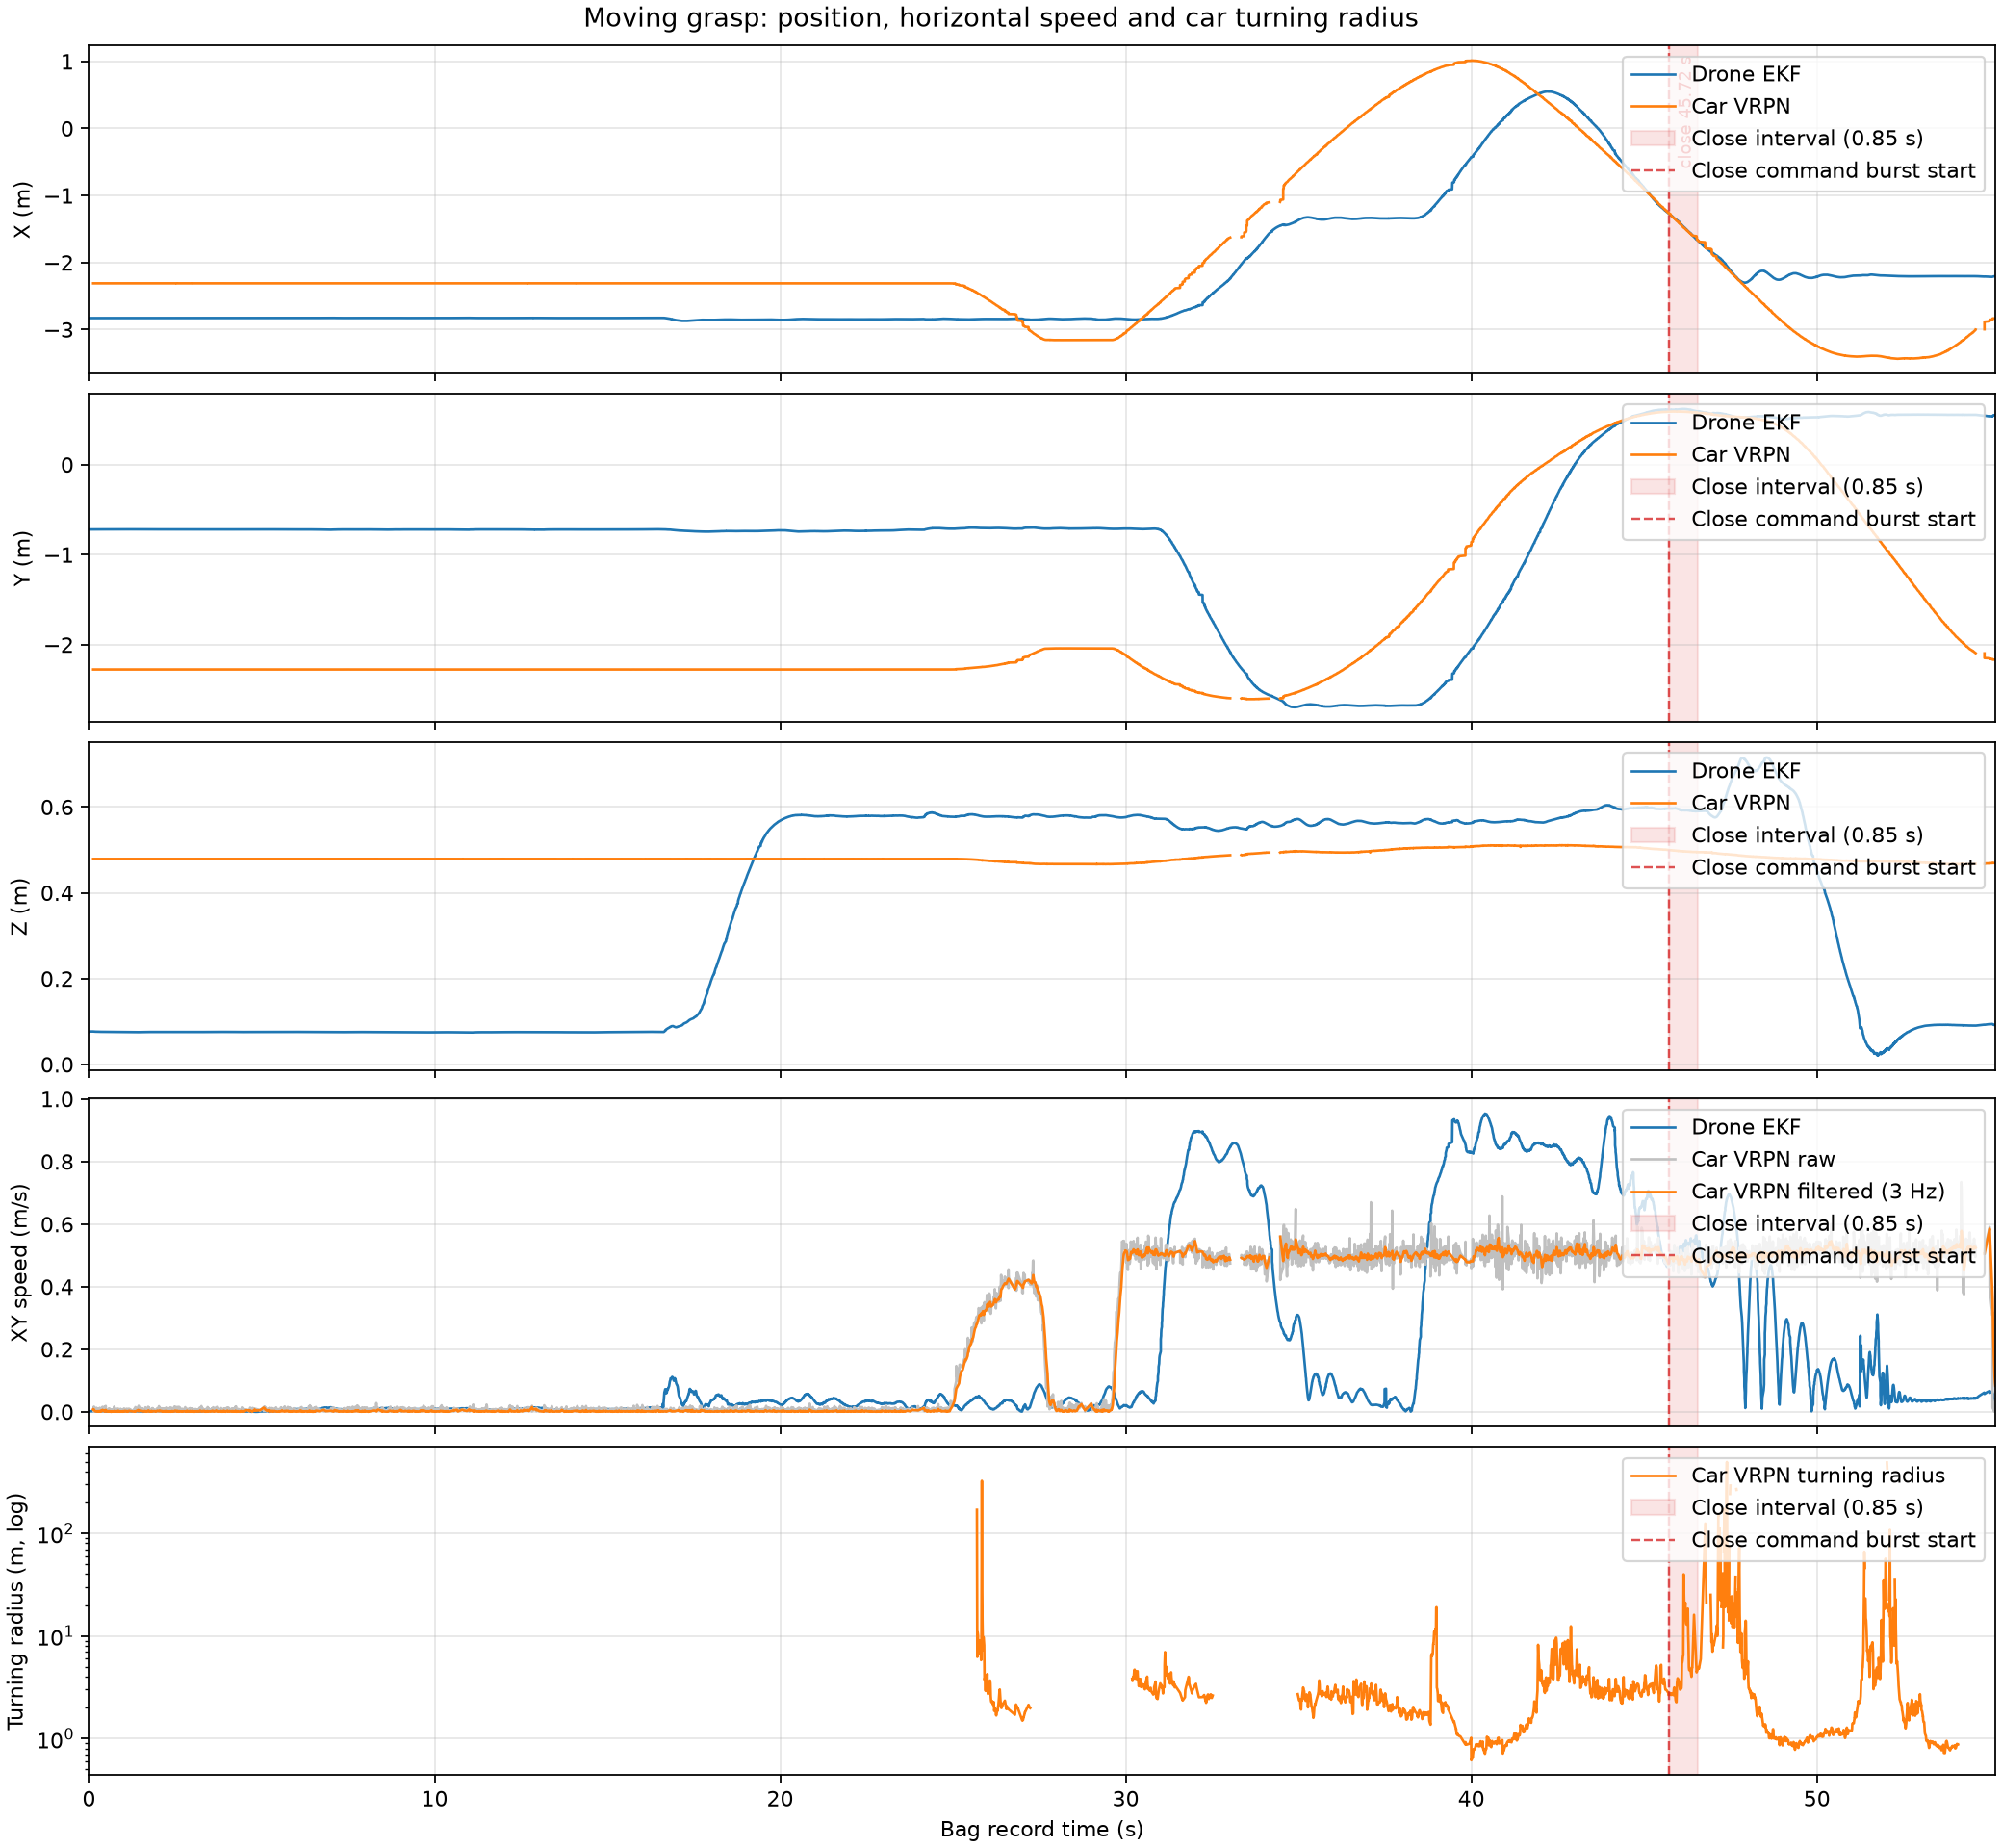

闭爪窗口 1: [45.716, 46.566) s; 样本 70; 数据覆盖: 完整
  滤波后小车 XY 最大速度: 0.505 m/s，时刻 46.443 s
  原始小车 XY 最大速度: 0.539 m/s，时刻 46.393 s
  首次闭爪指令时刻的小车转弯半径: 2.661 m（最近采样 45.715 s，离线估计）


In [118]:
import json

def read_timeseries_extras(path):
    commands, drone_velocity, targets = [], [], []
    snapshot_topic = '/drone0/planning/rosparam_snapshot'
    command_topic = '/flygripper/actuator_command'
    with AnyReader([path]) as reader:
        bag_start = reader.start_time * 1e-9
        conns = [c for c in reader.connections if c.topic in (TOPICS['drone'], snapshot_topic, command_topic)]
        topics_present = {c.topic for c in conns}
        for connection, timestamp, raw in reader.messages(connections=conns):
            msg = reader.deserialize(raw, connection.msgtype)
            t = timestamp * 1e-9 - bag_start
            if connection.topic == TOPICS['drone']:
                v = msg.twist.twist.linear
                if np.isfinite([v.x, v.y, v.z]).all():
                    drone_velocity.append((t, v.x, v.y, v.z))
            elif connection.topic == command_topic:
                if np.isfinite(msg.reference_position):
                    commands.append((t, int(msg.mode), float(msg.reference_position)))
            else:
                try:
                    value = json.loads(msg.data)['parameters']['grasp_position']
                    value = float(value)
                    if np.isfinite(value):
                        targets.append(value)
                except (KeyError, TypeError, ValueError, json.JSONDecodeError):
                    warnings.warn('无法解析规划参数快照中的 grasp_position。')
    v = np.asarray(drone_velocity, dtype=float).reshape(-1, 4)
    if len(v) == 0:
        raise ValueError('EKF 没有有效的速度样本')
    v = v[np.argsort(v[:, 0], kind='stable')]
    _, idx = np.unique(v[:, 0], return_index=True)
    v = v[idx]
    # The planner publishes grasp_position directly as a float64 position target.
    # Only use the snapshot when all recorded values agree; otherwise do not guess.
    if targets and all(np.isclose(value, targets[-1], rtol=1e-9, atol=1e-9) for value in targets):
        target, source = targets[-1], 'planner snapshot'
    else:
        target, source = None, 'unavailable or inconsistent snapshots'
        warnings.warn('规划快照中无唯一的 grasp_position，无法识别闭爪指令。')
    if command_topic not in topics_present:
        warnings.warn('bag 未记录 actuator_command，无法标记闭爪指令。')
    if CLOSE_BURST_GAP_S <= 0 or CLOSE_DURATION_S <= 0:
        raise ValueError('指令分组间隔和持续时间须大于零')
    matches = np.asarray([t for t, mode, pos in commands
                          if target is not None and mode == 0 and np.isclose(pos, target, rtol=1e-9, atol=1e-9)])
    starts = matches[np.r_[True, np.diff(matches) > CLOSE_BURST_GAP_S]] if len(matches) else np.array([])
    print(f'闭爪目标: {target} rad ({source}); 匹配指令 {len(matches)} 条，分组开始: {starts.round(3).tolist()} s')
    return v, starts, len(matches)

def line_with_gaps(ax, values, label, color, break_before=None):
    times = values[:, 0]
    y = values[:, 1].copy()
    # Add NaNs between samples to preserve both sides of a data outage.
    breaks = np.flatnonzero(np.diff(times) > MAX_GAP_S) + 1
    if break_before is not None:
        breaks = np.union1d(breaks, np.flatnonzero(break_before))
    ax.plot(np.insert(times, breaks, np.nan), np.insert(y, breaks, np.nan), label=label, color=color, lw=1.2)

def car_xy_curvature(velocity, min_speed_mps, max_gap_s, window_s):
    """Signed XY curvature from filtered velocity using a record-time window."""
    if not all(np.isfinite(x) and x > 0 for x in (min_speed_mps, max_gap_s, window_s)):
        raise ValueError('曲率最低速度、差分窗口及 MAX_GAP_S 须为有限正值')
    t = velocity[:, 0]
    speed = np.linalg.norm(velocity[:, 1:3], axis=1)
    result = np.column_stack((t, np.full(len(t), np.nan)))
    if len(t) < 3:
        return result
    left = np.searchsorted(t, t - window_s / 2, side='right') - 1
    right = np.searchsorted(t, t + window_s / 2, side='left')
    inside = (left >= 0) & (right < len(t))
    indices = np.flatnonzero(inside)
    lo, hi = left[indices], right[indices]
    # Prefix sums check every sample and interval in each window without crossing gaps.
    bad_speed = np.r_[0, np.cumsum(speed < min_speed_mps)]
    dt = np.diff(t)
    bad_gap = np.r_[0, np.cumsum((dt <= 0) | (dt > max_gap_s))]
    valid = ((bad_speed[hi + 1] - bad_speed[lo] == 0) &
             (bad_gap[hi] - bad_gap[lo] == 0))
    indices, lo, hi = indices[valid], lo[valid], hi[valid]
    acceleration = (velocity[hi, 1:3] - velocity[lo, 1:3]) / (t[hi] - t[lo])[:, None]
    v = velocity[indices, 1:3]
    result[indices, 1] = (v[:, 0] * acceleration[:, 1] - v[:, 1] * acceleration[:, 0]) / speed[indices]**3
    return result

def plot_timeseries(data, drone_velocity, close_starts):
    start = max(0.0, START_S)
    end = min(max(a[-1, 0] for a in data.values()), END_S if END_S is not None else float('inf'))
    if end <= start:
        raise ValueError('时间范围无效')
    fig, axes = plt.subplots(5, 1, figsize=(13, 12), sharex=True, constrained_layout=True)
    for i, axis in enumerate(axes[:3]):
        for key, color, label in [('drone', 'tab:blue', 'Drone EKF'), ('car', 'tab:orange', 'Car VRPN')]:
            a = data[key]
            line_with_gaps(axis, a[:, [0, i+1]], label, color)
        axis.set_ylabel(f'{"XYZ"[i]} (m)')
    car_velocity = data['velocity']
    line_with_gaps(axes[3], np.column_stack((drone_velocity[:,0], np.linalg.norm(drone_velocity[:,1:3], axis=1))), 'Drone EKF', 'tab:blue')
    line_with_gaps(axes[3], np.column_stack((car_velocity[:,0], np.linalg.norm(car_velocity[:,1:3], axis=1))), 'Car VRPN raw', 'silver')
    line_with_gaps(axes[3], np.column_stack((car_velocity_filtered[:,0], np.linalg.norm(car_velocity_filtered[:,1:3], axis=1))), f'Car VRPN filtered ({CAR_VELOCITY_CUTOFF_HZ:g} Hz)' if CAR_VELOCITY_CUTOFF_HZ else 'Car VRPN (filter off)', 'tab:orange')
    axes[3].set_ylabel('XY speed (m/s)')
    curvature = car_xy_curvature(car_velocity_filtered, CAR_CURVATURE_MIN_SPEED_MPS, MAX_GAP_S, CAR_CURVATURE_WINDOW_S)
    kappa = curvature[:, 1]
    radius = np.full(len(kappa), np.nan)
    with np.errstate(divide='ignore', over='ignore', invalid='ignore'):
        np.divide(1.0, np.abs(kappa), out=radius, where=np.isfinite(kappa) & (kappa != 0))
    radius[~np.isfinite(radius)] = np.nan
    sign_change = np.r_[False, (kappa[1:] * kappa[:-1] < 0)]
    line_with_gaps(axes[4], np.column_stack((curvature[:, 0], radius)),
                   'Car VRPN turning radius', 'tab:orange', break_before=sign_change)
    axes[4].set_yscale('log')
    axes[4].set_ylabel('Turning radius (m, log)')
    axes[4].set_xlabel('Bag record time (s)')
    for axis in axes:
        axis.set_xlim(start, end)
        axis.grid(True, alpha=0.3)
        intervals = [t for t in close_starts if t <= end and t + CLOSE_DURATION_S >= start]
        for i, t in enumerate(intervals):
            axis.axvspan(t, t+CLOSE_DURATION_S, color='tab:red', alpha=0.12,
                         label=f'Close interval ({CLOSE_DURATION_S:g} s)' if i == 0 else None)
            if start <= t <= end:
                axis.axvline(t, color='tab:red', linestyle='--', lw=1.1, alpha=0.8,
                             label='Close command burst start' if i == 0 else None)
        axis.legend(loc='upper right')
    visible = [t for t in close_starts if start <= t <= end]
    for t in visible:
        axes[0].annotate(f'close {t:.2f} s', xy=(t, 1), xycoords=('data', 'axes fraction'),
                         xytext=(4, -5), textcoords='offset points', va='top', color='tab:red', fontsize=8, rotation=90)
    fig.suptitle('Moving grasp: position, horizontal speed and car turning radius')
    TIMESERIES_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(TIMESERIES_OUTPUT, dpi=160)
    plt.close(fig)
    print(f'时序图: {TIMESERIES_OUTPUT}; 显示 {len(visible)} 个闭爪指令分组开始时刻')
    display(Image(filename=str(TIMESERIES_OUTPUT)))

def report_close_window_peak(raw, filtered, starts):
    if len(starts) == 0:
        print('没有可识别的闭爪指令，无法统计闭爪窗口速度。')
        return
    curvature = car_xy_curvature(filtered, CAR_CURVATURE_MIN_SPEED_MPS, MAX_GAP_S, CAR_CURVATURE_WINDOW_S)
    for i, start in enumerate(starts, 1):
        end = start + CLOSE_DURATION_S
        mask = (raw[:, 0] >= start) & (raw[:, 0] < end)
        idx = np.flatnonzero(mask)
        left = np.searchsorted(raw[:, 0], start, side='right') - 1
        right = np.searchsorted(raw[:, 0], end, side='left')
        complete = left >= 0 and right < len(raw) and np.all(np.diff(raw[left:right+1, 0]) <= MAX_GAP_S)
        print(f'闭爪窗口 {i}: [{start:.3f}, {end:.3f}) s; 样本 {len(idx)}; 数据覆盖: {"完整" if complete else "不完整"}')
        if len(idx) == 0:
            print('  无速度样本，无法计算最大值。')
        else:
            for label, a in [('滤波后', filtered), ('原始', raw)]:
                speeds = np.linalg.norm(a[idx, 1:3], axis=1)
                peak_index = idx[int(np.argmax(speeds))]
                print(f'  {label}小车 XY 最大速度: {speeds.max():.3f} m/s，时刻 {a[peak_index, 0]:.3f} s')
        # Require an exact sample or two bracketing samples with no outage.
        times = curvature[:, 0]
        right = np.searchsorted(times, start, side='left')
        exact = right < len(times) and times[right] == start
        bracketed = 0 < right < len(times) and times[right] - times[right-1] <= MAX_GAP_S
        if exact:
            nearest = right
        elif bracketed:
            nearest = min((right-1, right), key=lambda j: abs(times[j] - start))
        else:
            nearest = None
        if nearest is None or not np.isfinite(curvature[nearest, 1]):
            print('  首次闭爪指令时刻的小车转弯半径: 无法计算（速度过低、数据缺口或差分窗口不完整）')
        elif curvature[nearest, 1] == 0:
            print(f'  首次闭爪指令时刻的小车转弯半径: 无穷大（曲率为零，采样 {times[nearest]:.3f} s）')
        else:
            radius = 1.0 / abs(curvature[nearest, 1])
            print(f'  首次闭爪指令时刻的小车转弯半径: {radius:.3f} m（最近采样 {times[nearest]:.3f} s，离线估计）')

drone_velocity, close_starts, close_command_count = read_timeseries_extras(BAG)
plot_timeseries(data, drone_velocity, close_starts)
report_close_window_peak(data['velocity'], car_velocity_filtered, close_starts)

GIF: 数据 0.12–55.16 s | 2x | 213 帧 | 帧延迟 130 ms | 预计播放 27.69 s
GIF: /Users/lzf/Documents/wfzf/2026-11-02-18-03-36_moving_grasp.gif | 0.12–55.16 s | 213 frames


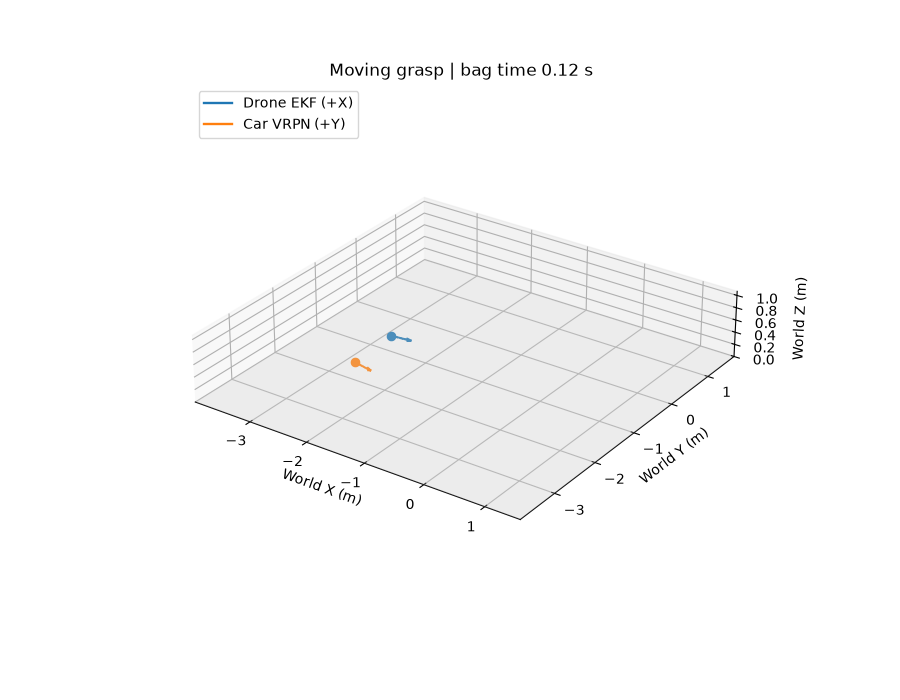

In [119]:
def sample(a, t):
    """线性插值；缺口和数据范围之外返回 None。四元数先处理双重覆盖。"""
    i = np.searchsorted(a[:, 0], t)
    if i < len(a) and abs(a[i, 0] - t) < 1e-9:
        return a[i, 1:].copy()
    if i == 0 or i == len(a) or a[i, 0] - a[i-1, 0] > MAX_GAP_S:
        return None
    u = (t - a[i-1, 0]) / (a[i, 0] - a[i-1, 0])
    left, right = a[i-1, 1:].copy(), a[i, 1:].copy()
    if len(left) == 7 and np.dot(left[3:], right[3:]) < 0:
        right[3:] *= -1
    result = left * (1-u) + right * u
    if len(result) == 7:
        norm = np.linalg.norm(result[3:])
        if norm < 1e-12:
            return None
        result[3:] /= norm
    return result

def direction(q, axis):
    # quaternion (x,y,z,w) rotates body axis into world
    xyz, w = q[:3], q[3]
    return axis + 2 * np.cross(xyz, np.cross(xyz, axis) + w * axis)

def gif_timing(data):
    """GIF 延迟以 10 ms 为单位；两种动画共享相同的时间采样。"""
    if not all(np.isfinite(x) and x > 0 for x in (FPS, PLAYBACK_SPEED, MAX_GAP_S, GIF_DPI)):
        raise ValueError('FPS、PLAYBACK_SPEED、MAX_GAP_S 和 GIF_DPI 必须为有限正数')
    start = max(START_S, *(a[0, 0] for a in data.values()))
    end = min(*(a[-1, 0] for a in data.values()), END_S if END_S is not None else float('inf'))
    if not np.isfinite(start) or not np.isfinite(end) or end <= start:
        raise ValueError('指定时间范围内没有三个话题的共同时间段')
    # Pillow/GIF 保存帧延迟的精度为 10 ms；先量化，再用于计算帧数。
    frame_ms = max(10, int(np.floor(100.0 / FPS + 0.5)) * 10)
    gif_fps = 1000.0 / (frame_ms + 0.000001)
    frame_count = max(2, int(np.ceil((end-start) * (1000.0/frame_ms) / PLAYBACK_SPEED)) + 1)
    times = np.linspace(start, end, frame_count)
    print(f'GIF: 数据 {start:.2f}–{end:.2f} s | {PLAYBACK_SPEED:g}x | '
          f'{frame_count} 帧 | 帧延迟 {frame_ms} ms | 预计播放 {frame_count*frame_ms/1000:.2f} s')
    return start, end, times, gif_fps

def make_gif(data):
    start, end, times, gif_fps = gif_timing(data)
    positions = np.concatenate([a[(a[:, 0]>=start)&(a[:, 0]<=end), 1:4] for k,a in data.items() if k != 'velocity'])
    if not len(positions):
        raise ValueError('时间范围内没有位置样本')
    lo, hi = positions.min(axis=0), positions.max(axis=0)
    lo[2], hi[2] = min(lo[2], 0.0), max(hi[2], 0.0)
    center = (lo + hi) / 2
    span = max(float((hi-lo).max()) * 1.25, 0.5)
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_xlim(center[0]-span/2, center[0]+span/2)
    ax.set_ylim(center[1]-span/2, center[1]+span/2)
    zmin = lo[2] - 0.1 if lo[2] < 0 else 0.0
    zmax = max(hi[2] + HEADING_LENGTH_M, zmin + 0.5)
    ax.set_zlim(zmin, zmax)
    ax.set_box_aspect((span, span, zmax-zmin))
    gx = np.array([center[0]-span/2, center[0]+span/2])
    gy = np.array([center[1]-span/2, center[1]+span/2])
    xx, yy = np.meshgrid(gx, gy)
    ax.plot_surface(xx, yy, np.zeros_like(xx), color='lightgray', alpha=0.25, shade=False)
    ax.set(xlabel='World X (m)', ylabel='World Y (m)', zlabel='World Z (m)')
    ax.view_init(elev=28, azim=-55)
    lines = {k: ax.plot([], [], [], color=color, lw=1.7, label=label)[0]
             for k, color, label in [('drone', 'tab:blue', 'Drone EKF (+X)'), ('car', 'tab:orange', 'Car VRPN (+Y)')]}
    ax.legend(loc='upper left')
    moving = []
    def update(t):
        while moving:
            moving.pop().remove()
        for k, color, axis in [('drone', 'tab:blue', np.array([1.,0.,0.])), ('car', 'tab:orange', np.array([0.,1.,0.]))]:
            a = data[k]
            path = a[(a[:,0]>=start)&(a[:,0]<=t)]
            # Break visible trails at missing-data gaps.
            if len(path):
                xyz = path[:,1:4].copy()
                xyz[np.r_[False, np.diff(path[:,0]) > MAX_GAP_S]] = np.nan
                lines[k].set_data_3d(xyz[:,0], xyz[:,1], xyz[:,2])
            state = sample(a, t)
            if state is not None:
                p = state[:3]; d = direction(state[3:], axis) * HEADING_LENGTH_M
                moving.append(ax.scatter(*p, color=color, s=35))
                moving.append(ax.quiver(*p, *d, color=color, arrow_length_ratio=0.25))
        ax.set_title(f'Moving grasp | bag time {t:.2f} s')
        return list(lines.values()) + moving
    ani = FuncAnimation(fig, update, frames=times, interval=1000/gif_fps, blit=False)
    OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    ani.save(str(OUTPUT), writer=PillowWriter(fps=gif_fps), dpi=GIF_DPI)
    plt.close(fig)
    print(f'GIF: {OUTPUT} | {start:.2f}–{end:.2f} s | {len(times)} frames')
    display(Image(filename=str(OUTPUT)))

if MAKE_GIF:
    make_gif(data)

## XY 平面轨迹 GIF
俯视图显示位置、朝向在 XY 平面的投影和小车的水平速度。轨迹不包含高度信息。 小车速度箭头使用配置的 XY 低通滤波结果。

GIF: 数据 0.12–55.16 s | 2x | 213 帧 | 帧延迟 130 ms | 预计播放 27.69 s
XY GIF: /Users/lzf/Documents/wfzf/2026-11-02-18-03-36_moving_grasp_xy.gif | 0.12–55.16 s | 213 frames


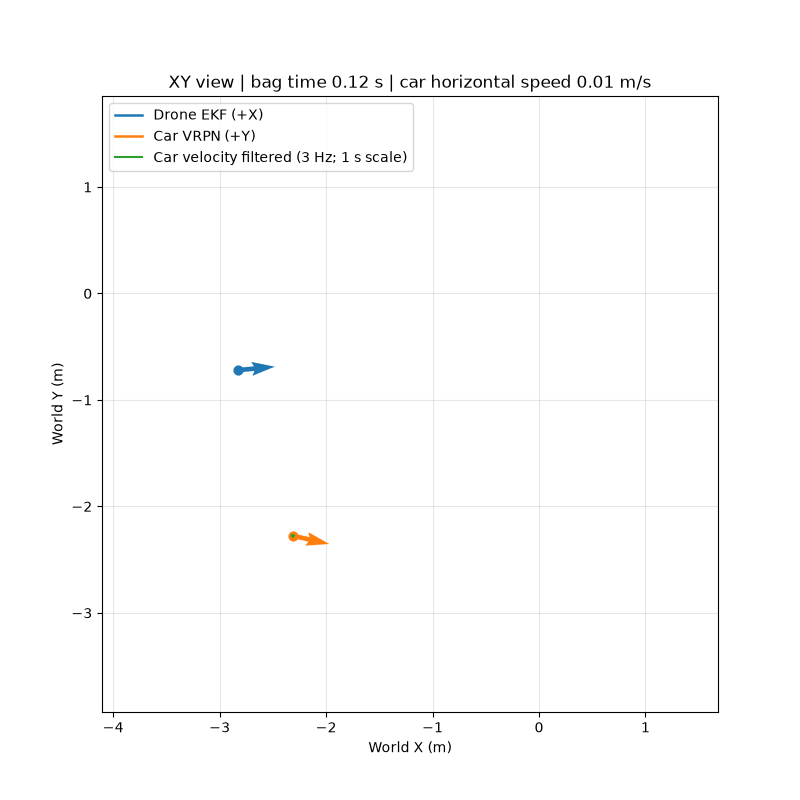

In [120]:
def make_xy_gif(data):
    start, end, times, gif_fps = gif_timing(data)
    positions = np.concatenate([a[(a[:,0]>=start)&(a[:,0]<=end),1:3]
                                for k, a in data.items() if k != 'velocity'])
    if not len(positions):
        raise ValueError('时间范围内没有位置样本')
    lo, hi = positions.min(axis=0), positions.max(axis=0)
    center = (lo + hi) / 2
    span = max(float((hi-lo).max()) * 1.3, 0.5)
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.set_xlim(center[0]-span/2, center[0]+span/2)
    ax.set_ylim(center[1]-span/2, center[1]+span/2)
    ax.set_aspect('equal', adjustable='box')
    ax.set(xlabel='World X (m)', ylabel='World Y (m)')
    ax.grid(True, alpha=0.3)
    lines = {k: ax.plot([], [], color=color, lw=1.8, label=label)[0]
             for k, color, label in [('drone', 'tab:blue', 'Drone EKF (+X)'),
                                      ('car', 'tab:orange', 'Car VRPN (+Y)')]}
    ax.plot([], [], color='tab:green', label=f'Car velocity filtered ({CAR_VELOCITY_CUTOFF_HZ:g} Hz; {VELOCITY_SCALE_S:g} s scale)' if CAR_VELOCITY_CUTOFF_HZ else f'Car velocity raw ({VELOCITY_SCALE_S:g} s scale)')
    ax.legend(loc='upper left')
    moving = []
    def update(t):
        while moving:
            moving.pop().remove()
        states = {}
        for k, color, axis in [('drone', 'tab:blue', np.array([1., 0., 0.])),
                               ('car', 'tab:orange', np.array([0., 1., 0.]))]:
            a = data[k]
            path = a[(a[:,0]>=start)&(a[:,0]<=t)]
            if len(path):
                xy = path[:,1:3].copy()
                xy[np.r_[False, np.diff(path[:,0]) > MAX_GAP_S]] = np.nan
                lines[k].set_data(xy[:,0], xy[:,1])
            state = sample(a, t)
            states[k] = state
            if state is not None:
                p = state[:2]
                heading = direction(state[3:], axis)[:2] * HEADING_LENGTH_M
                moving.append(ax.scatter(*p, color=color, s=40, zorder=4))
                moving.append(ax.quiver(*p, *heading, color=color, angles='xy',
                                        scale_units='xy', scale=1, zorder=5))
        vel = sample(car_velocity_filtered, t)
        if states['car'] is not None and vel is not None:
            moving.append(ax.quiver(*states['car'][:2], *(vel[:2] * VELOCITY_SCALE_S),
                                    color='tab:green', angles='xy', scale_units='xy',
                                    scale=1, zorder=5))
        speed = f'{np.linalg.norm(vel[:2]):.2f} m/s' if vel is not None else 'unavailable'
        ax.set_title(f'XY view | bag time {t:.2f} s | car horizontal speed {speed}')
        return list(lines.values()) + moving
    ani = FuncAnimation(fig, update, frames=times, interval=1000/gif_fps, blit=False)
    XY_GIF_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
    ani.save(str(XY_GIF_OUTPUT), writer=PillowWriter(fps=gif_fps), dpi=GIF_DPI)
    plt.close(fig)
    print(f'XY GIF: {XY_GIF_OUTPUT} | {start:.2f}–{end:.2f} s | {len(times)} frames')
    display(Image(filename=str(XY_GIF_OUTPUT)))

if MAKE_XY_GIF:
    make_xy_gif(data)